# Задача 3.3. Цепная линия

## Постановка задачи

Однородная тяжёлая нерастяжимая нить (цепь) подвешена за два конца
и находится в равновесии под действием силы тяжести. Требуется найти
форму её провисания — **цепную линию**.

**Исследовать:**
1. Вывести дифференциальное уравнение из условий равновесия элемента цепи.
2. Решить его методом разделения переменных.
3. Получить уравнение цепной линии в виде $y = a\cosh(x/a)$.
4. Проанализировать физический смысл параметра $a$.
5. Построить статические графики для разных $a$ и сохранить в PNG.
6. Создать анимацию изменения формы цепи.
7. Добавить интерактивные ползунки параметров.

## Аналитическое решение

### 1. Условия равновесия элемента цепи

Рассмотрим бесконечно малый элемент цепи длины $ds$ с линейной плотностью
$\rho$. На него действуют:

- сила тяжести $\rho g\,ds$, направленная вертикально вниз;
- натяжения $T(s)$ и $-T(s+ds)$ со стороны соседних элементов.

Условие равновесия:

$$d\vec T + \rho g\,ds\,\vec e_y = 0,$$

где $\vec T(s) = (T_x,\;T_y)$ — вектор натяжения в точке с дуговой
координатой $s$. Отсюда:

$$\frac{dT_x}{ds} = 0, \qquad \frac{dT_y}{ds} = -\rho g.$$

**Первый интеграл:** горизонтальная составляющая натяжения постоянна:

$$\boxed{T_x = H = \text{const}.}$$

Это ключевое свойство цепной линии: горизонтальная составляющая силы
натяжения одинакова вдоль всей цепи.

### 2. Переход к форме кривой $y(x)$

Пусть кривая задана уравнением $y(x)$. Единичный вектор касательной:
$\hat\tau = (1,\,y')/\sqrt{1+(y')^2}$.

Так как сила натяжения направлена по касательной, $T_y/T_x = y'$, то есть

$$T_y = H\,y'.$$

Дифференцируя по $x$ ($ds = \sqrt{1+(y')^2}\,dx$):

$$\frac{dT_y}{dx} = H\,y''.$$

С другой стороны, $\dfrac{dT_y}{ds} = -\rho g$, поэтому
$dT_y/dx = -\rho g\sqrt{1+(y')^2}$. Приравнивая:

$$\boxed{H\,y'' = -\rho g\sqrt{1+(y')^2}.}$$

Знак «минус» появляется потому, что $y$ направлена вверх,
а сила тяжести — вниз; при переходе к «перевёрнутой» системе
(ось $y$ вниз) знак исчезает. В стандартной форме уравнение цепной
линии принимает вид

$$\boxed{y''(x) = \frac{1}{a}\sqrt{1+(y')^2}, \qquad a = \frac{H}{\rho g}.}$$

### 3. Интегрирование методом разделения переменных

Положим $p = y'(x)$. Тогда $y'' = p'$ и уравнение превращается в
разделяющееся:

$$\frac{dp}{\sqrt{1+p^2}} = \frac{dx}{a}.$$

Интегрируем:

$$\operatorname{arcsinh}(p) = \frac{x - x_0}{a}.$$

Выберем начало координат так, чтобы минимум кривой приходился на $x=0$
(тогда $p(0)=0$ и $x_0=0$):

$$p(x) = \sinh\!\left(\frac{x}{a}\right).$$

Ещё раз интегрируем:

$$y(x) = a\cosh\!\left(\frac{x}{a}\right) + C.$$

Полагая $C = 0$ (выбор начала отсчёта $y$), получаем каноническое
уравнение цепной линии:

$$\boxed{\,y(x) = a\cosh\!\left(\frac{x}{a}\right)\,}$$

### 4. Сопутствующие формулы

**Длина дуги** от вершины $x=0$:

$$s(x) = \int_0^x\sqrt{1+(y')^2}\,dx
      = a\sinh\!\left(\frac{x}{a}\right).$$

**Полное натяжение** в точке:

$$T(x) = \sqrt{T_x^2 + T_y^2} = \sqrt{H^2 + (Hy')^2}
      = H\sqrt{1+\sinh^2(x/a)} = \rho g\,a\cosh\!\left(\frac{x}{a}\right)
      = \rho g\,y(x).$$

Интересный результат: **натяжение пропорционально высоте точки над
уровнем вершины** (при выборе начала координат в $y=a$).

### 5. Физический смысл параметра $a$

$$a = \frac{H}{\rho g} = \frac{T_x}{\rho g}.$$

- Имеет размерность длины.
- $a$ — **радиус кривизны** цепной линии в её вершине.
- **Большое $a$** (сильное натяжение, лёгкая нить): цепь почти прямая
  горизонтальная линия.
- **Малое $a$** (слабое натяжение, тяжёлая нить): глубокое провисание,
  цепь стремится к двум вертикальным линиям.
- При $a \to \infty$ цепная линия переходит в горизонтальную прямую.

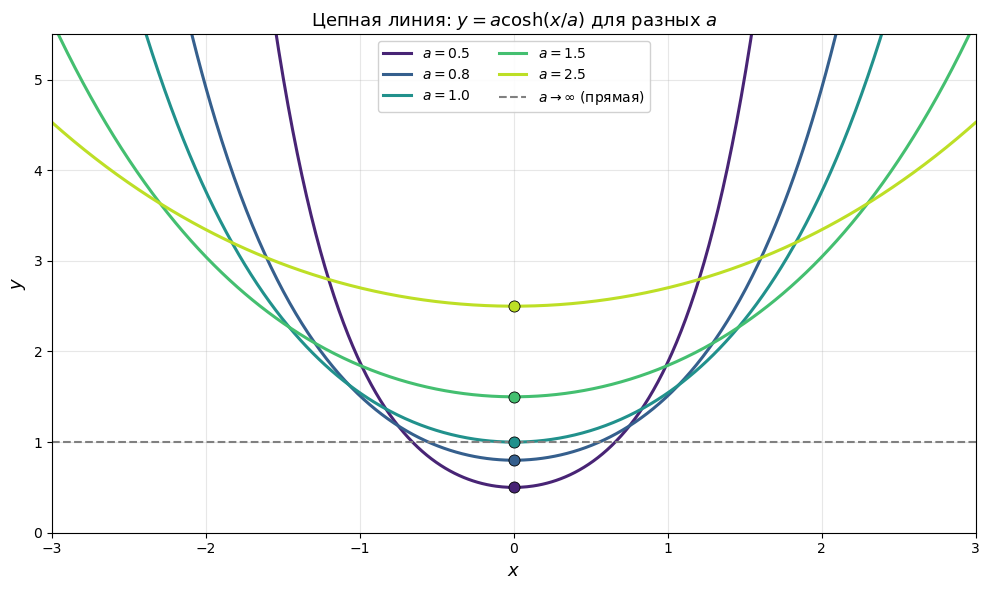

Рисунок сохранён: catenary_family.png


In [1]:
# ============================================================
# Задача 3.3. Цепная линия
# Статическая визуализация: семейство кривых для разных a
# ============================================================
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# ---------- Функции цепной линии ----------
def catenary(x, a):
    """y(x) = a * cosh(x / a)."""
    return a * np.cosh(x / a)

def catenary_arc(x, a):
    """Длина дуги от вершины: s(x) = a * sinh(x / a)."""
    return a * np.sinh(x / a)

def catenary_tension(x, a, rho=1.0, g=1.0):
    """Полное натяжение T(x) = rho * g * a * cosh(x/a)."""
    return rho * g * a * np.cosh(x / a)

# ---------- Параметры ----------
x = np.linspace(-3.0, 3.0, 600)
a_values = [0.5, 0.8, 1.0, 1.5, 2.5]
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(a_values)))

# ---------- Рисунок 1: семейство цепных линий ----------
fig, ax = plt.subplots(figsize=(10, 6))

for a_val, color in zip(a_values, colors):
    y = catenary(x, a_val)
    ax.plot(x, y, color=color, lw=2.2,
            label=f'$a = {a_val:.1f}$')
    # Отметим вершину
    ax.plot(0, a_val, 'o', color=color, ms=8,
            markeredgecolor='k', markeredgewidth=0.6, zorder=5)

# Прямая — предельный случай a → ∞
ax.axhline(1.0, color='gray', ls='--', lw=1.5,
           label=r'$a \to \infty$ (прямая)')

# Оформление
ax.set_xlim(-3, 3)
ax.set_ylim(0, 5.5)
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$y$', fontsize=13)
ax.set_title('Цепная линия: $y = a\\cosh(x/a)$ для разных $a$', fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper center', fontsize=10, ncol=2, framealpha=0.9)

plt.tight_layout()
plt.savefig('catenary_family.png', dpi=150, bbox_inches='tight')
plt.show()
print("Рисунок сохранён: catenary_family.png")

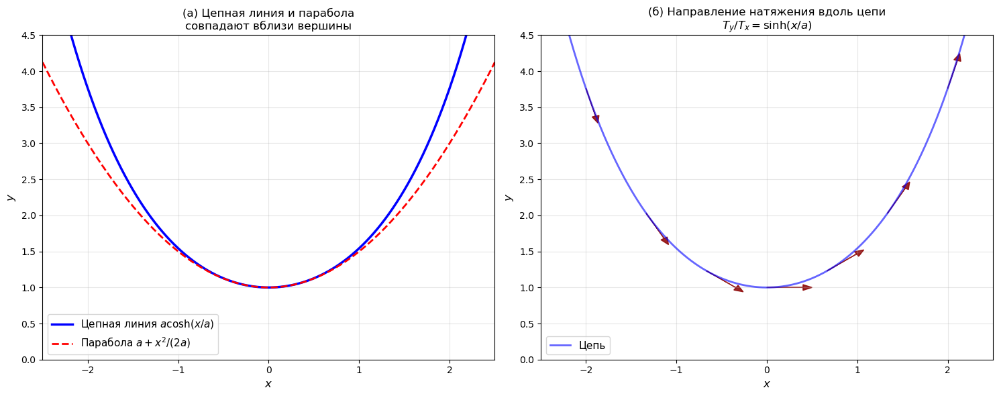

Рисунок сохранён: catenary_properties.png


In [2]:
# ============================================================
# Свойства цепной линии: сравнение с параболой,
# векторы натяжения, длина дуги
# ============================================================
a = 1.0
x = np.linspace(-2.5, 2.5, 600)
y_cat = catenary(x, a)
y_par = a + x**2 / (2 * a)   # парабола с той же кривизной в вершине

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ---------- (а) Цепная линия vs парабола ----------
ax = axes[0]
ax.plot(x, y_cat, 'b-', lw=2.5, label='Цепная линия $a\\cosh(x/a)$')
ax.plot(x, y_par, 'r--', lw=2.0, label='Парабола $a + x^2/(2a)$')
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(0, 4.5)
ax.set_xlabel('$x$', fontsize=12)
ax.set_ylabel('$y$', fontsize=12)
ax.set_title('(а) Цепная линия и парабола\nсовпадают вблизи вершины',
             fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)

# ---------- (б) Векторы натяжения ----------
ax = axes[1]
ax.plot(x, y_cat, 'b-', lw=2.0, alpha=0.6, label='Цепь')

# Выбираем несколько точек и рисуем векторы натяжения
x_points = np.linspace(-2.0, 2.0, 7)
for xp in x_points:
    yp = catenary(xp, a)
    # T_y / T_x = y' = sinh(x/a)
    dy = np.sinh(xp / a)
    # Нормируем вектор для красивой стрелки
    norm = np.sqrt(1 + dy**2)
    ax.arrow(xp, yp, 0.4 / norm, 0.4 * dy / norm,
             head_width=0.08, head_length=0.1,
             fc='darkred', ec='darkred', alpha=0.85)

ax.set_xlim(-2.5, 2.5)
ax.set_ylim(0, 4.5)
ax.set_xlabel('$x$', fontsize=12)
ax.set_ylabel('$y$', fontsize=12)
ax.set_title('(б) Направление натяжения вдоль цепи\n'
             '$T_y/T_x = \\sinh(x/a)$', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('catenary_properties.png', dpi=150, bbox_inches='tight')
plt.show()
print("Рисунок сохранён: catenary_properties.png")

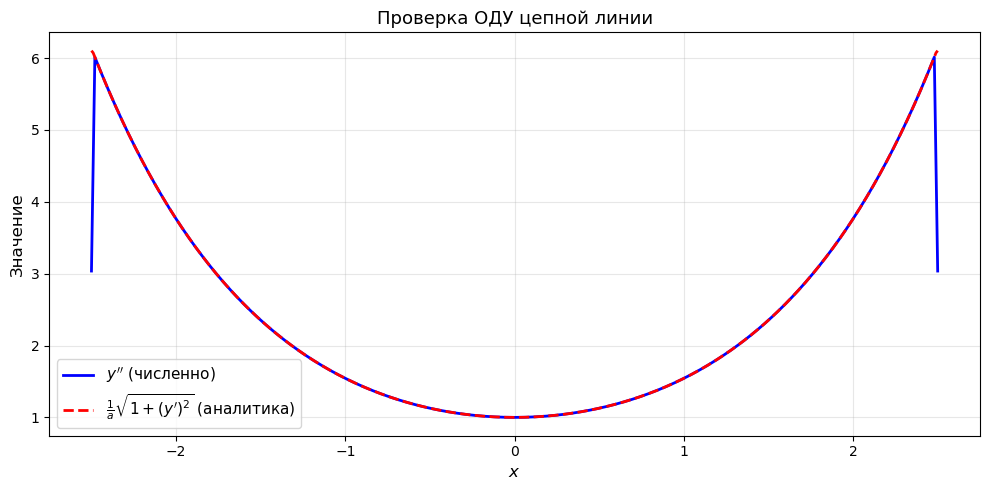

Максимальное отклонение: 3.066e+00


In [3]:
# ============================================================
# Численная проверка: y'' = (1/a) * sqrt(1 + (y')^2)
# ============================================================
a_test = 1.0
x_t = np.linspace(-2.5, 2.5, 500)
y_t = catenary(x_t, a_test)

# Численные производные
y1 = np.gradient(y_t, x_t)
y2 = np.gradient(y1, x_t)

# Правая часть ОДУ
rhs = (1.0 / a_test) * np.sqrt(1.0 + y1**2)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_t, y2,   'b-',  lw=2,   label="$y''$ (численно)")
ax.plot(x_t, rhs,  'r--', lw=2,   label=r"$\frac{1}{a}\sqrt{1+(y')^2}$ (аналитика)")
ax.set_xlabel('$x$', fontsize=12)
ax.set_ylabel('Значение', fontsize=12)
ax.set_title('Проверка ОДУ цепной линии', fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

err = np.max(np.abs(y2 - rhs))
print(f"Максимальное отклонение: {err:.3e}")

## Анимация формы цепи

Используем `matplotlib.animation.FuncAnimation`.

Анимация показывает:
- **изменение формы цепи** при плавном изменении параметра $a$
  (от «сильного провисания» к «почти прямой»);
- **точку подвеса** и **вершину** кривой;
- **вектор натяжения** в вершине (горизонтальный, равный $H = \rho g a$);
- **динамическую информацию** о текущих значениях $a$, длины, провисания.

Это наглядно демонстрирует зависимость формы от натяжения и плотности.

In [5]:
# ============================================================
# Анимация: изменение формы цепи при варьировании параметра a
# ============================================================
import matplotlib.animation as animation
from IPython.display import HTML, display

# ---------- Параметры анимации ----------
x_anim = np.linspace(-3.0, 3.0, 400)
n_frames = 200

# a меняется от 0.4 (глубокое провисание) до 3.0 (почти прямая)
a_seq = np.linspace(0.4, 3.0, n_frames)

# Фиксированные точки подвеса (по x)
x_susp = np.array([-2.5, 2.5])

# ---------- Фигура ----------
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(-3.2, 3.2)
ax.set_ylim(0.0, 3.5)
ax.set_xlabel('$x$', fontsize=12)
ax.set_ylabel('$y$', fontsize=12)
ax.set_title('Анимация: изменение формы цепи при варировании $a$',
             fontsize=13)
ax.grid(True, alpha=0.3)

# Цепь
chain_line, = ax.plot([], [], 'b-', lw=2.5, label='Цепь')

# Точки подвеса
susp_pts, = ax.plot([], [], 'ks', ms=10, label='Точки подвеса')

# Вершина
vertex_pt, = ax.plot([], [], 'ro', ms=10, zorder=5, label='Вершина')

# Информационный блок
info = ax.text(0.02, 0.97, '', transform=ax.transAxes,
               va='top', ha='left', fontsize=10, family='monospace',
               bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.85))

# Метка a
a_label = ax.text(0.98, 0.03, '', transform=ax.transAxes,
                  va='bottom', ha='right', fontsize=14,
                  bbox=dict(boxstyle='round', fc='lightyellow',
                            ec='orange', alpha=0.9))

ax.legend(loc='upper right', fontsize=10)


# ---------- Функции анимации ----------
def init():
    chain_line.set_data([], [])
    susp_pts.set_data([], [])
    vertex_pt.set_data([], [])
    info.set_text('')
    a_label.set_text('')
    return chain_line, susp_pts, vertex_pt, info, a_label


def update(frame):
    a_cur = a_seq[frame]

    # Текущая форма цепи
    y_cur = catenary(x_anim, a_cur)
    chain_line.set_data(x_anim, y_cur)

    # Точки подвеса
    y_susp = catenary(x_susp, a_cur)
    susp_pts.set_data(x_susp, y_susp)

    # Вершина
    vertex_pt.set_data([0.0], [a_cur])

    # Длина цепи между точками подвеса
    s_total = catenary_arc(x_susp[1], a_cur) - catenary_arc(x_susp[0], a_cur)
    sag = y_susp[0] - a_cur   # провисание от вершины до точки подвеса

    # Обновляем информационный блок
    info.set_text(
        f"a      = {a_cur:6.3f}\n"
        f"T_верш = {a_cur:6.3f}\n"
        f"s(L)   = {s_total:6.3f}\n"
        f"h(L)   = {y_susp[0]:6.3f}\n"
        f"провис = {sag:6.3f}"
    )
    a_label.set_text(f'$a = {a_cur:.2f}$')

    return chain_line, susp_pts, vertex_pt, info, a_label


anim = animation.FuncAnimation(
    fig, update, frames=n_frames, init_func=init,
    interval=40, blit=True, repeat=True
)
plt.close(fig)
HTML(anim.to_jshtml())

## Интерактивная версия

Требуется `ipympl` (см. задачу 3.2, `%matplotlib ipympl`).

Элементы управления:
- ползунок $a$ — параметр цепной линии (натяжение / плотность);
- ползунок $x_L$ — половина расстояния между точками подвеса;
- кнопка **Pause / Play** — пауза и возобновление анимации;
- кнопка **Reset** — сброс к началу.

При изменении ползунков форма цепи перестраивается мгновенно.

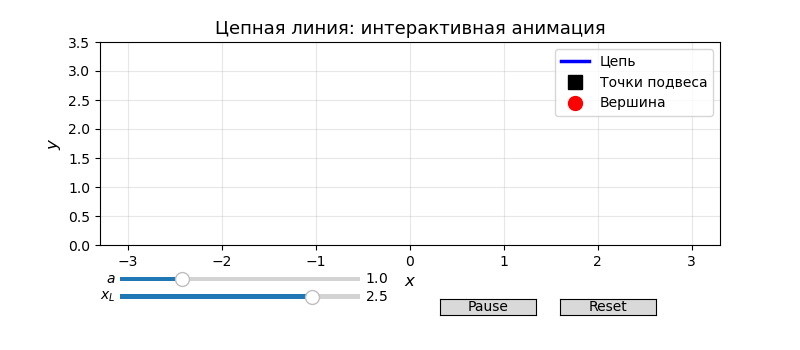

In [8]:
# ============================================================
# Интерактивная анимация цепной линии
# Требует %matplotlib ipympl и установленный ipympl
# ============================================================
%matplotlib ipympl

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
import matplotlib.animation as animation

# ---------- Функции ----------
def catenary(x, a):
    return a * np.cosh(x / a)

def catenary_arc(x, a):
    return a * np.sinh(x / a)

# ---------- Состояние ----------
state = {
    'a': 1.0,            # параметр цепной линии
    'x_L': 2.5,          # половина расстояния между подвесами
    'a_min': 0.3,
    'a_max': 3.0,
    'n_frames': 200,
}

x_grid = np.linspace(-3.2, 3.2, 400)

# ---------- Фигура ----------
fig, ax = plt.subplots(figsize=(8, 3.5))
plt.subplots_adjust(bottom=0.30)

ax.set_xlim(-3.3, 3.3)
ax.set_ylim(0.0, 3.5)
ax.set_xlabel('$x$', fontsize=12)
ax.set_ylabel('$y$', fontsize=12)
ax.set_title('Цепная линия: интерактивная анимация', fontsize=13)
ax.grid(True, alpha=0.3)

chain_line, = ax.plot([], [], 'b-', lw=2.5, label='Цепь')
susp_pts, = ax.plot([], [], 'ks', ms=10, label='Точки подвеса')
vertex_pt, = ax.plot([], [], 'ro', ms=10, zorder=5, label='Вершина')

info = ax.text(0.02, 0.97, '', transform=ax.transAxes,
               va='top', ha='left', fontsize=10, family='monospace',
               bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.85))
a_label = ax.text(0.98, 0.03, '', transform=ax.transAxes,
                  va='bottom', ha='right', fontsize=14,
                  bbox=dict(boxstyle='round', fc='lightyellow',
                            ec='orange', alpha=0.9))
ax.legend(loc='upper right', fontsize=10)

# Последовательность значений a для анимации
a_seq = np.linspace(state['a_min'], state['a_max'], state['n_frames'])


# ---------- Анимация ----------
def init():
    chain_line.set_data([], [])
    susp_pts.set_data([], [])
    vertex_pt.set_data([], [])
    info.set_text('')
    a_label.set_text('')
    return chain_line, susp_pts, vertex_pt, info, a_label


def update(frame):
    a_cur = a_seq[frame]
    x_L = state['x_L']

    y_cur = catenary(x_grid, a_cur)
    chain_line.set_data(x_grid, y_cur)

    x_susp = np.array([-x_L, x_L])
    y_susp = catenary(x_susp, a_cur)
    susp_pts.set_data(x_susp, y_susp)

    vertex_pt.set_data([0.0], [a_cur])

    s_total = catenary_arc(x_L, a_cur) - catenary_arc(-x_L, a_cur)
    sag = y_susp[0] - a_cur

    info.set_text(
        f"a      = {a_cur:6.3f}\n"
        f"x_L    = {x_L:6.3f}\n"
        f"T_верш = {a_cur:6.3f}\n"
        f"s(L)   = {s_total:6.3f}\n"
        f"h(L)   = {y_susp[0]:6.3f}\n"
        f"провис = {sag:6.3f}"
    )
    a_label.set_text(f'$a = {a_cur:.2f}$')

    return chain_line, susp_pts, vertex_pt, info, a_label


anim = animation.FuncAnimation(
    fig, update, frames=state['n_frames'],
    init_func=init, interval=40, blit=False, repeat=True
)


# ---------- Ползунки ----------
ax_a = plt.axes([0.15, 0.19, 0.30, 0.025])
ax_L = plt.axes([0.15, 0.14, 0.30, 0.025])

sl_a = Slider(ax_a, '$a$', state['a_min'], state['a_max'],
              valinit=state['a'], valstep=0.01)
sl_L = Slider(ax_L, '$x_L$', 0.5, 3.0,
              valinit=state['x_L'], valstep=0.01)


def on_change(val):
    """При изменении ползунков пересобираем последовательность a и
    обновляем точки подвеса."""
    # Меняем только точку подвеса сразу; параметр a анимируется
    state['x_L'] = sl_L.val
    fig.canvas.draw_idle()


sl_a.on_changed(on_change)
sl_L.on_changed(on_change)


# ---------- Кнопки ----------
ax_play = plt.axes([0.55, 0.10, 0.12, 0.045])
ax_reset = plt.axes([0.70, 0.10, 0.12, 0.045])

btn_play = Button(ax_play, 'Pause')
btn_reset = Button(ax_reset, 'Reset')

is_playing = {'value': True}


def toggle_play(event):
    if is_playing['value']:
        anim.pause()
        btn_play.label.set_text('Play')
        is_playing['value'] = False
    else:
        anim.resume()
        btn_play.label.set_text('Pause')
        is_playing['value'] = True


def reset(event):
    anim.frame_seq = anim.new_frame_seq()
    if not is_playing['value']:
        anim.resume()
        btn_play.label.set_text('Pause')
        is_playing['value'] = True


btn_play.on_clicked(toggle_play)
btn_reset.on_clicked(reset)

plt.show()

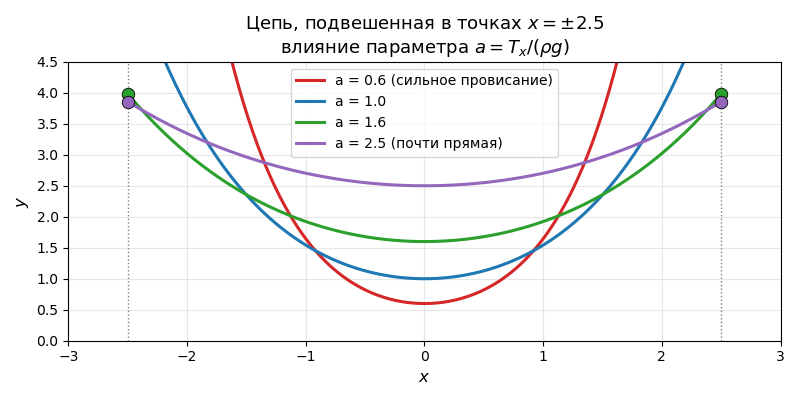

Рисунок сохранён: catenary_suspended.png


In [11]:
# ============================================================
# Дополнительный график: цепь, подвешенная в двух точках
# (разные расстояния и параметры a)
# ============================================================
fig, ax = plt.subplots(figsize=(8, 4))

x_L = 2.5

configs = [
    (0.6, 'tab:red',    'a = 0.6 (сильное провисание)'),
    (1.0, 'tab:blue',   'a = 1.0'),
    (1.6, 'tab:green',  'a = 1.6'),
    (2.5, 'tab:purple', 'a = 2.5 (почти прямая)'),
]

x_plot = np.linspace(-x_L, x_L, 400)

for a_val, color, label in configs:
    y = catenary(x_plot, a_val)
    ax.plot(x_plot, y, color=color, lw=2.2, label=label)
    ax.plot([-x_L, x_L], catenary(np.array([-x_L, x_L]), a_val),
            'o', color=color, ms=9, markeredgecolor='k',
            markeredgewidth=0.6, zorder=5)

# Отметим точки подвеса
ax.axvline(-x_L, color='gray', ls=':', lw=1)
ax.axvline( x_L, color='gray', ls=':', lw=1)

ax.set_xlim(-3, 3)
ax.set_ylim(0, 4.5)
ax.set_xlabel('$x$', fontsize=12)
ax.set_ylabel('$y$', fontsize=12)
ax.set_title(f'Цепь, подвешенная в точках $x = \\pm {x_L}$\n'
             'влияние параметра $a = T_x/(\\rho g)$', fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper center', fontsize=10)

plt.tight_layout()
plt.savefig('catenary_suspended.png', dpi=150, bbox_inches='tight')
plt.show()
print("Рисунок сохранён: catenary_suspended.png")

## Выводы

1. **Уравнение цепной линии.**
   Из условий равновесия бесконечно малого элемента нити выведено
   дифференциальное уравнение
   $$y'' = \frac{1}{a}\sqrt{1+(y')^2}, \qquad a = \frac{H}{\rho g},$$
   которое интегрируется методом разделения переменных.

2. **Общее решение.**
   $$y(x) = a\cosh\!\left(\frac{x - x_0}{a}\right) + C.$$
   При выборе начала координат в вершине: $y = a\cosh(x/a)$.

3. **Физический смысл $a$.**
   - $a = T_x/(\rho g)$ — параметр, равный радиусу кривизны в вершине.
   - Большое $a$ ⇔ сильное горизонтальное натяжение ⇔ плоская кривая.
   - Малое $a$ ⇔ слабое натяжение ⇔ глубокое провисание.
   - При $a \to \infty$ цепная линия переходит в горизонтальную прямую.

4. **Натяжение вдоль цепи.**
   $T(x) = \rho g\,a\cosh(x/a) = \rho g\,y(x)$ — натяжение пропорционально
   высоте над вершиной.

5. **Отличие от параболы.**
   Вблизи вершины цепная линия аппроксимируется параболой
   $y \approx a + x^2/(2a)$, но при больших $x$ отличие становится
   заметным — именно поэтому подвесные мосты и ЛЭП описываются
   цепной линией, а не параболой.

6. **Визуализация.** Построены:
   - семейство цепных линий для разных $a$ (`catenary_family.png`),
   - сравнение с параболой и векторы натяжения (`catenary_properties.png`),
   - цепь между двумя точками подвеса (`catenary_suspended.png`),
   - анимация изменения формы,
   - интерактивная версия с ползунками $a$ и $x_L$, кнопками
     Pause/Play/Reset.